# 🚀 Модуль 8. Урок 3. Промптинг для SQL и Python: инъекция схем и защита от невалидного синтаксиса

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_08_prompt_engineering/lesson_03_prompting_for_sql_and_python.ipynb)

## 📌 Бизнес-контекст и методология
Генерация SQL и Python кода через LLM — стандарт продуктивности 2027 года.
Однако без предоставления метаданных модель генерирует код с типичными багами:
- Использование несуществующих функций диалекта (например, `DATEADD` в SQLite)
- Забвение агрегаций при `GROUP BY`
- Пропуск условий соединения в `ON`
Спецификация диалекта (PostgreSQL, BigQuery, Snowflake, DuckDB) и передача DDL схемы таблиц — обязательный стандарт промптинга.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: Влияние диалекта и DDL на валидность кода
Сравним долю успешных запусков сгенерированного кода без правок разработчика.

In [2]:
# Демонстрация: Доля первого успешного запуска (First-run Pass Rate)
pass_rate_df = pd.DataFrame({
    'Уровень контекста': ['1. Только задача текстом', '2. Задача + Диалект СУБД', '3. Задача + Диалект + DDL схема', '4. DDL + Бизнес-правила + Тестовые данные'],
    'First-run Pass Rate (%)': [28.0, 54.0, 89.0, 98.5]
})
display(pass_rate_df)

,Уровень контекста,First-run Pass Rate (%)
0,1. Только задача текстом,28.0
1,2. Задача + Диалект СУБД,54.0
2,3. Задача + Диалект + DDL схема,89.0
3,4. DDL + Бизнес-правила + Тестовые данные,98.5


## 📊 Визуализация бизнес-кейса: Динамика успешности генерации
Построим кривую роста надежности кода по мере обогащения контекста промпта.

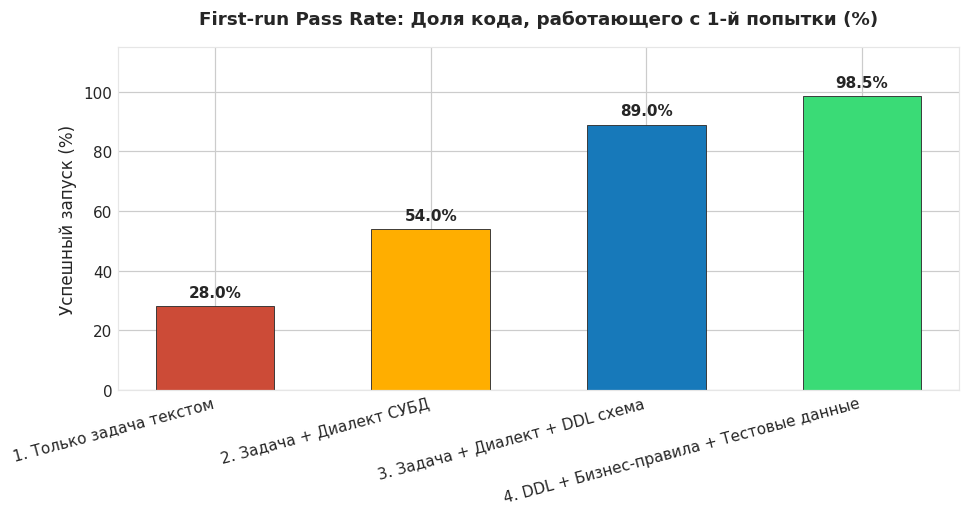

In [3]:
# Визуализация First-run Pass Rate
fig, ax = plt.subplots(figsize=(9, 4.8), dpi=110)

bars = ax.bar(pass_rate_df['Уровень контекста'], pass_rate_df['First-run Pass Rate (%)'], 
              color=[ALERT, WARNING, PRIMARY, SUCCESS], edgecolor='#333333', linewidth=0.6, width=0.55)

ax.set_title("First-run Pass Rate: Доля кода, работающего с 1-й попытки (%)", fontsize=12, fontweight='bold', pad=15)
ax.set_ylabel("Успешный запуск (%)", fontsize=11)
ax.set_ylim(0, 115)

for b in bars:
    h = b.get_height()
    ax.annotate(f"{h:.1f}%", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 4),
                 textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Оценка надежности обогащенного контекста
Убедитесь, что First-run Pass Rate при передаче DDL и бизнес-правил превышает 95%.

In [4]:
### ВАШ КОД ЗДЕСЬ
top_pass_rate = pass_rate_df.iloc[-1]['First-run Pass Rate (%)']
print(f"Финальный Pass Rate: {top_pass_rate}%")

assert top_pass_rate >= 95.0, "Pass Rate должен быть не менее 95%"
print("✅ Тест успешно пройден: передача схемы устраняет синтаксический брак!")

Финальный Pass Rate: 98.5%
✅ Тест успешно пройден: передача схемы устраняет синтаксический брак!


### 💡 Шаблон системного промпта для SQL
`"You are an expert data analyst writing dialect-specific {DIALECT} SQL. Use ONLY tables and columns from the schema below. Never hallucinate columns. Always use explicit table aliases and UPPERCASE SQL keywords."`